In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [8]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset shape after removing duplicates:", df.shape)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value  

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Dataset shape after removing duplicates: (20640, 10)


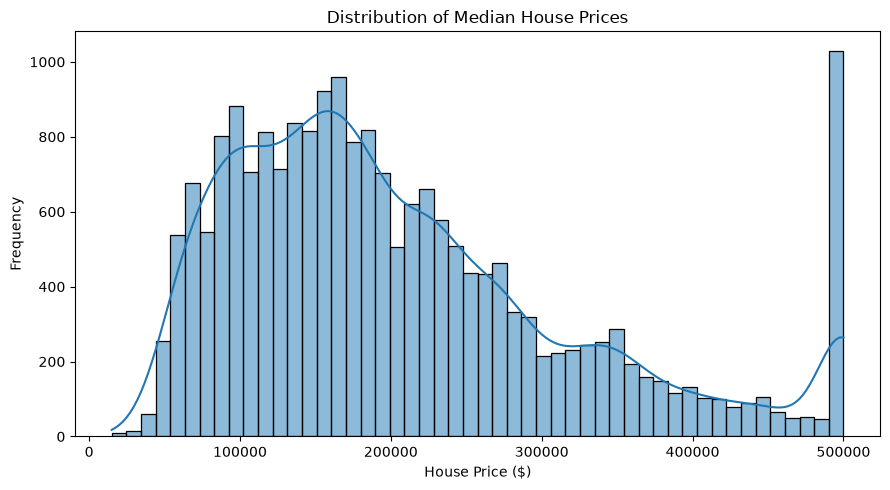

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(df["median_house_value"], bins=50, kde=True)

plt.title("Distribution of Median House Prices")
plt.xlabel("House Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("outputs/house_price_distribution.png", dpi=300)
plt.show()

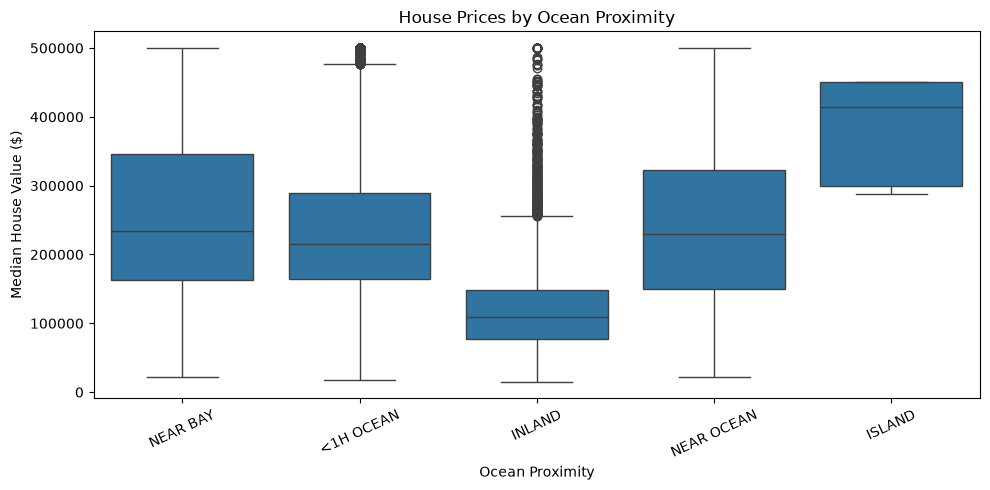

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)

plt.title("House Prices by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value ($)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("outputs/house_prices_by_ocean.png", dpi=300)
plt.show()

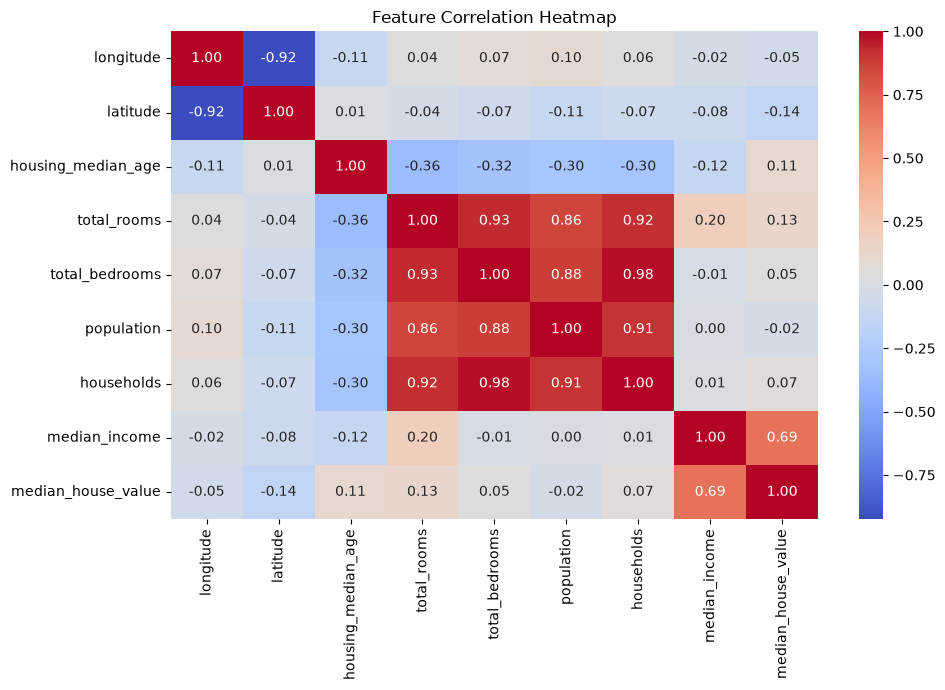

In [11]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png", dpi=300)
plt.show()

In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [12]:
target = "median_house_value"

X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Feature shape: (20640, 9)
Target shape: (20640,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


In [19]:
from sklearn.preprocessing import OneHotEncoder

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("All imports successful!")
print("OneHotEncoder:", OneHotEncoder)

All imports successful!
OneHotEncoder: <class 'sklearn.preprocessing._encoders.OneHotEncoder'>


In [22]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Training Linear Regression...
Training Ridge Regression...
Training Random Forest...
All models trained successfully!
MODEL PERFORMANCE COMPARISON


,MAE,RMSE,R2 Score
Model,,,
Random Forest,31634.83,49044.86,0.82
Linear Regression,50670.49,70059.19,0.63
Ridge Regression,50676.92,70066.02,0.63



Best Model: Random Forest
MAE: $31,634.83
RMSE: $49,044.86
R2 Score: 0.8164


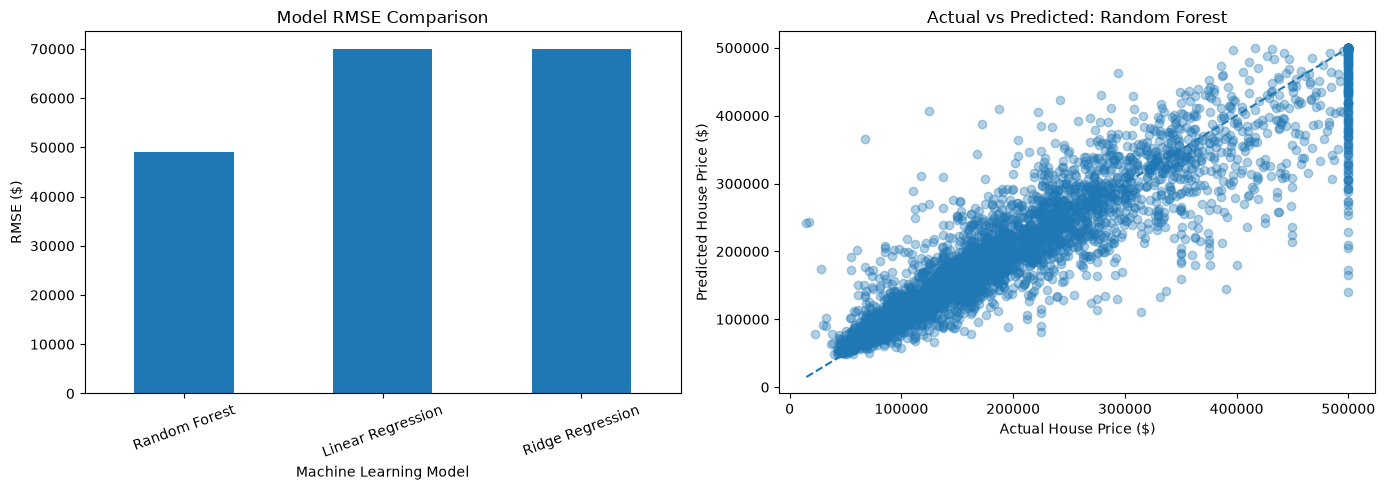

Visualization saved as output.png
SAMPLE HOUSE DETAILS


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
20046,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,INLAND


Actual Price: $47,700.00
Predicted Price: $50,395.29
Absolute Difference: $2,695.29


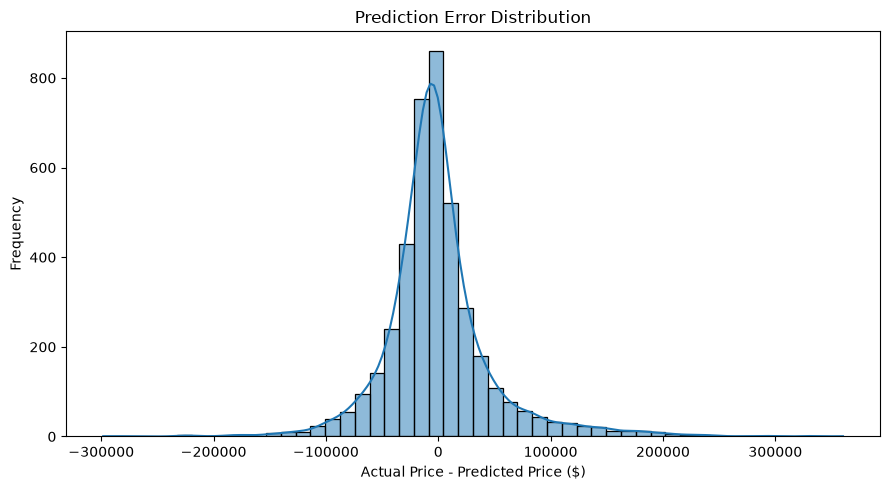

HOUSING PRICE PREDICTION PROJECT COMPLETED
Dataset shape: (20640, 10)
Training samples: 16512
Testing samples: 4128
Models trained: 3
Best model: Random Forest

Final Performance:


,MAE,RMSE,R2 Score
Model,,,
Random Forest,31634.83,49044.86,0.82
Linear Regression,50670.49,70059.19,0.63
Ridge Regression,50676.92,70066.02,0.63



Generated files:

./
- README.md
- Task2_Housing_Price_Prediction.ipynb
- output.png
- requirements.txt

outputs/
- best_housing_model.pkl
- correlation_heatmap.png
- house_price_distribution.png
- house_prices_by_ocean.png
- model_comparison.csv
- model_comparison.png
- prediction_results.csv
- residual_distribution.png

Main visualization: output.png
Trained model: outputs/best_housing_model.pkl
PROJECT COMPLETED SUCCESSFULLY!


In [23]:
# ============================================
# CELL 11: TRAIN MACHINE LEARNING MODELS
# ============================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("outputs", exist_ok=True)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = {}
predictions_by_model = {}

for name, model in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions_by_model[name] = predictions

    results[name] = {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    }

print("All models trained successfully!")


# ============================================
# CELL 12: MODEL EVALUATION AND COMPARISON
# ============================================

results_df = pd.DataFrame(results).T
results_df.index.name = "Model"
results_df = results_df.sort_values(by="RMSE")

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(2))

results_df.to_csv("outputs/model_comparison.csv")

best_model_name = results_df.index[0]
best_model = trained_models[best_model_name]
y_pred = predictions_by_model[best_model_name]

print("\nBest Model:", best_model_name)
print(f"MAE: ${results_df.iloc[0]['MAE']:,.2f}")
print(f"RMSE: ${results_df.iloc[0]['RMSE']:,.2f}")
print(f"R2 Score: {results_df.iloc[0]['R2 Score']:.4f}")


# ============================================
# CELL 13: VISUALIZE MODEL PERFORMANCE
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Model comparison
results_df["RMSE"].plot(
    kind="bar",
    ax=axes[0],
    title="Model RMSE Comparison"
)

axes[0].set_xlabel("Machine Learning Model")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=20)

# Actual vs predicted prices
axes[1].scatter(y_test, y_pred, alpha=0.35)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

axes[1].plot(
    [low, high],
    [low, high],
    linestyle="--"
)

axes[1].set_title(f"Actual vs Predicted: {best_model_name}")
axes[1].set_xlabel("Actual House Price ($)")
axes[1].set_ylabel("Predicted House Price ($)")

plt.tight_layout()

plt.savefig("output.png", dpi=300, bbox_inches="tight")
plt.savefig(
    "outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved as output.png")


# ============================================
# CELL 14: SAMPLE PREDICTION AND ERROR ANALYSIS
# ============================================

sample_house = X_test.iloc[[0]]

actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_house)[0]

print("SAMPLE HOUSE DETAILS")
display(sample_house)

print(f"Actual Price: ${actual_price:,.2f}")
print(f"Predicted Price: ${predicted_price:,.2f}")
print(
    f"Absolute Difference: "
    f"${abs(actual_price - predicted_price):,.2f}"
)

# Save predictions
residuals = y_test.to_numpy() - y_pred

prediction_results = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred,
    "Absolute Error": np.abs(residuals)
})

prediction_results.to_csv(
    "outputs/prediction_results.csv",
    index=False
)

# Residual distribution
plt.figure(figsize=(9, 5))

sns.histplot(residuals, bins=50, kde=True)

plt.title("Prediction Error Distribution")
plt.xlabel("Actual Price - Predicted Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("outputs/residual_distribution.png", dpi=300)
plt.show()


# ============================================
# CELL 15: SAVE MODEL AND FINAL SUMMARY
# ============================================

joblib.dump(
    best_model,
    "outputs/best_housing_model.pkl"
)

print("=" * 50)
print("HOUSING PRICE PREDICTION PROJECT COMPLETED")
print("=" * 50)

print("Dataset shape:", df.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Models trained:", len(trained_models))
print("Best model:", best_model_name)

print("\nFinal Performance:")
display(results_df.round(2))

print("\nGenerated files:")

for folder in [".", "outputs"]:
    print(f"\n{folder}/")

    for filename in sorted(os.listdir(folder)):
        path = os.path.join(folder, filename)

        if os.path.isfile(path):
            print("-", filename)

print("\nMain visualization: output.png")
print("Trained model: outputs/best_housing_model.pkl")
print("PROJECT COMPLETED SUCCESSFULLY!")